In [1]:
#Setup of the Code, importing the necessary libraries and setting up the data directory path.
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("..") / "data"

In [2]:
# Import both LG datasets from the local data folder.
LG_DIR = DATA_DIR / "01_LG_Electronics_Appliances"

df_reviews = pd.read_csv(LG_DIR / "appliance_brand_reviews.csv")
df_behavior = pd.read_csv(LG_DIR / "electronics_market_behavior.csv")

print("Reviews:", df_reviews.shape)
print("Market behavior:", df_behavior.shape)


Reviews: (20004, 14)
Market behavior: (649605, 8)


In [3]:
# 1. Session scope and display settings
# Source: LG_TV_Coding_Session_Plan_Steps4_5_EN.pdf, 4 November 2026.
# Today we audit measurement and comparability before estimating any Logit model.
# The reviews remain loaded for context, but cannot be joined to the TV event data:
# the course dictionary states that the two files contain different products/users.
# Run all cells from top to bottom with Marketing-Project as the working directory.
import matplotlib.pyplot as plt
from IPython.display import display

KEY = ['user_id', 'session_id', 'product_id']
BRANDS = ['lg', 'samsung']
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
BRAND_COLORS = {'lg': '#A50034', 'samsung': '#1428A0'}
# Tables store unrounded values. Display formatting never changes a calculation.


In [ ]:
# 2. Audit the raw behavioral input without changing df_behavior or either CSV
# Dates are interpreted in UTC, as specified by the data dictionary.
# Invalid inputs are reported before we stop; no row is silently discarded.
required_columns = {
    'event_time', 'event_type', 'user_id', 'session_id', 'product_id',
    'product_category', 'brand', 'price'
}
assert required_columns.issubset(df_behavior.columns), 'Required input columns are missing.'
events = df_behavior.copy(deep=True)
events['event_time'] = pd.to_datetime(events['event_time'], utc=True, errors='coerce')
events['price'] = pd.to_numeric(events['price'], errors='coerce')
exact_duplicate_count = int(df_behavior.duplicated().sum())
product_mapping = events.groupby('product_id').agg(
    brands=('brand', 'nunique'), categories=('product_category', 'nunique')
)
shared_session_ids = events.groupby('session_id')['user_id'].nunique()
shared_session_ids = shared_session_ids[shared_session_ids > 1]
invalid_price = events['price'].isna() | ~np.isfinite(events['price']) | events['price'].le(0)
unexpected_events = ~events['event_type'].isin(['view', 'cart', 'purchase'])
data_quality = pd.DataFrame({
    'check': ['Raw rows', 'Raw columns', 'Exact duplicate rows after the first copy',
              'Invalid or missing timestamps', 'Invalid, missing or non-positive prices',
              'Missing identifier cells', 'Unexpected event types',
              'Products mapped to multiple brands', 'Products mapped to multiple categories',
              'Session IDs shared by multiple users'],
    'value': [len(events), len(df_behavior.columns), exact_duplicate_count,
              int(events['event_time'].isna().sum()), int(invalid_price.sum()),
              int(events[KEY].isna().sum().sum()), int(unexpected_events.sum()),
              int(product_mapping['brands'].gt(1).sum()),
              int(product_mapping['categories'].gt(1).sum()), len(shared_session_ids)]
})
display(data_quality)
display(df_behavior.isna().sum().rename('missing_cells').to_frame())
display(pd.DataFrame({'first_event_utc': [events['event_time'].min()],
                      'last_event_utc': [events['event_time'].max()]}))
assert not events.isna().any().any(), 'Missing/invalid values require an explicit cleaning decision.'
assert not invalid_price.any(), 'Prices require investigation before cohort construction.'
assert not unexpected_events.any(), 'Unexpected event types require investigation.'
assert product_mapping.eq(1).all().all(), 'Product mappings are inconsistent.'
# Shared session IDs are retained: including user_id in KEY prevents merging different people.
# Duplicate events are retained in the baseline and tested separately below.


,check,value
0,Raw rows,649605
1,Raw columns,8
2,Exact duplicate rows after the first copy,1247
3,Invalid or missing timestamps,0
4,"Invalid, missing or non-positive prices",0
5,Missing identifier cells,0
6,Unexpected event types,0
7,Products mapped to multiple brands,0
8,Products mapped to multiple categories,0
9,Session IDs shared by multiple users,4


,missing_cells
event_time,0
event_type,0
user_id,0
session_id,0
product_id,0
product_category,0
brand,0
price,0


,first_event_utc,last_event_utc
0,2019-10-01 00:06:07+00:00,2019-11-30 23:56:30+00:00


In [5]:
# 3. Apply the agreed scope in separate, visible stages
# This is an approved historical retail proxy, not proprietary LG or total-market data.
# The end date is exclusive, so every timestamp on 30 November remains eligible.
PERIOD_START = pd.Timestamp('2019-10-01', tz='UTC')
PERIOD_END = pd.Timestamp('2019-12-01', tz='UTC')
period_events = events.loc[events['event_time'].ge(PERIOD_START)
                           & events['event_time'].lt(PERIOD_END)].copy()
tv_events = period_events.loc[period_events['product_category'].eq('tv')].copy()
tv_brand_events = tv_events.loc[tv_events['brand'].isin(BRANDS)].copy()

def describe_event_stage(stage, frame, previous_count, note):
    # These are event counts. They must not be confused with binary purchase outcomes.
    return {'stage': stage, 'raw_event_rows': len(frame),
            'analytical_keys': len(frame[KEY].drop_duplicates()),
            'users': frame['user_id'].nunique(), 'products': frame['product_id'].nunique(),
            'raw_purchase_events': int(frame['event_type'].eq('purchase').sum()),
            'events_excluded_at_stage': previous_count - len(frame), 'notes': note}

audit_rows = [
    describe_event_stage('Raw file', events, len(events), 'Duplicates retained.'),
    describe_event_stage('October-November 2019', period_events, len(events), 'UTC date filter.'),
    describe_event_stage('TV category', tv_events, len(period_events), 'Other categories excluded.'),
    describe_event_stage('LG and Samsung TVs', tv_brand_events, len(tv_events), 'Other brands excluded.')
]
display(pd.DataFrame(audit_rows))


,stage,raw_event_rows,analytical_keys,users,products,raw_purchase_events,events_excluded_at_stage,notes
0,Raw file,649605,363382,138863,1613,10368,0,Duplicates retained.
1,October-November 2019,649605,363382,138863,1613,10368,0,UTC date filter.
2,TV category,212303,115750,50373,290,3785,437302,Other categories excluded.
3,LG and Samsung TVs,135411,74739,35885,196,2331,76892,Other brands excluded.


In [6]:
# 4. Build one product-consideration row per user, session and product
# A key is eligible only if it contains a view. Its first view defines time zero.
# A purchase counts only when it is strictly later than time zero in the same key.
# For presence-based outcomes, the last purchase is sufficient to test whether
# ANY purchase occurs after the first view or after the first eligible cart.
# No later cart or session-total variable should become a first-view model predictor.
def build_tv_cohort(event_frame):
    views = event_frame.loc[event_frame['event_type'].eq('view')]
    first_views = (views.sort_values('event_time', kind='stable')
                   .drop_duplicates(KEY, keep='first')
                   [KEY + ['brand', 'product_category', 'event_time', 'price']]
                   .rename(columns={'event_time': 'first_view_time', 'price': 'initial_price'}))
    # Equal-time first views with conflicting prices need a decision, not an arbitrary choice.
    first_view_rows = views.merge(first_views[KEY + ['first_view_time']], on=KEY, validate='many_to_one')
    tied_prices = (first_view_rows.loc[first_view_rows['event_time'].eq(first_view_rows['first_view_time'])]
                   .groupby(KEY)['price'].nunique())
    assert not tied_prices.gt(1).any(), 'Conflicting prices at the first-view timestamp.'

    last_purchases = (event_frame.loc[event_frame['event_type'].eq('purchase')]
                      .groupby(KEY)['event_time'].max().rename('last_purchase_time'))
    cohort = first_views.join(last_purchases, on=KEY)
    carts = event_frame.loc[event_frame['event_type'].eq('cart')].merge(
        first_views[KEY + ['first_view_time']], on=KEY, how='inner', validate='many_to_one')
    eligible_carts = carts.loc[carts['event_time'].gt(carts['first_view_time'])]
    first_carts = eligible_carts.groupby(KEY)['event_time'].min().rename('first_eligible_cart_time')
    cohort = cohort.join(first_carts, on=KEY)

    cohort['purchase_after_view'] = cohort['last_purchase_time'].gt(cohort['first_view_time'])
    cohort['cart_after_view'] = cohort['first_eligible_cart_time'].notna()
    cohort['purchase_after_cart'] = cohort['last_purchase_time'].gt(cohort['first_eligible_cart_time'])
    cohort['Y'] = cohort['purchase_after_view'].astype('int8')
    cohort['month'] = cohort['first_view_time'].dt.strftime('%Y-%m')
    # A cohort belongs to the month of its FIRST VIEW, even if its purchase is later.
    # Missing purchase/cart timestamps mean no qualifying event, not missing data to impute.
    cohort['purchase_without_qualifying_cart_path'] = (
        cohort['purchase_after_view'] & ~cohort['purchase_after_cart'])
    cohort['purchase_with_no_eligible_cart'] = (
        cohort['purchase_after_view'] & ~cohort['cart_after_view'])
    assert not cohort.duplicated(KEY).any(), 'The analytical key must be unique.'
    assert cohort['Y'].notna().all() and cohort['Y'].isin([0, 1]).all()
    assert not (cohort['purchase_after_cart'] & ~cohort['purchase_after_view']).any()
    assert not (cohort['purchase_after_cart'] & ~cohort['cart_after_view']).any()
    return cohort.sort_values(KEY).reset_index(drop=True)

baseline_full = build_tv_cohort(tv_brand_events)
print(f'Baseline: {len(baseline_full):,} consideration rows; '
      f'{baseline_full["Y"].sum():,} purchase outcomes.')
# Y=0 means no qualifying purchase was observed in this unit. It does not mean
# that the shopper never bought elsewhere, in another session or after the file ended.


Baseline: 74,712 consideration rows; 2,150 purchase outcomes.


In [7]:
# 5. Finish the audit trail and test whether exact duplicates affect the cohort
# Deduplication is a diagnostic here. It never silently replaces baseline_full.
deduplicated_events = tv_brand_events.drop_duplicates(subset=list(df_behavior.columns))
deduplicated_cohort = build_tv_cohort(deduplicated_events)
pd.testing.assert_frame_equal(baseline_full, deduplicated_cohort)
duplicate_invariance_verified = True
retained_key_events = tv_brand_events.merge(baseline_full[KEY], on=KEY, validate='many_to_one')
audit_rows.append(describe_event_stage(
    'Keys with at least one view', retained_key_events, len(tv_brand_events),
    'All events in eligible keys; temporal outcome rules are applied separately.'))
audit_summary = pd.DataFrame(audit_rows)
audit_summary['purchase_outcomes'] = pd.array([pd.NA] * len(audit_summary), dtype='Int64')
audit_summary.loc[audit_summary.index[-1], 'purchase_outcomes'] = int(baseline_full['Y'].sum())
display(audit_summary)
display(pd.DataFrame({
    'comparison': ['All raw-file duplicate rows', 'Duplicate rows in LG/Samsung TV events',
                   'Baseline cohort rows', 'Deduplicated cohort rows'],
    'count': [exact_duplicate_count, len(tv_brand_events) - len(deduplicated_events),
              len(baseline_full), len(deduplicated_cohort)]
}))
print('Exact deduplication leaves every analytical value unchanged. Baseline events remain intact.')


,stage,raw_event_rows,analytical_keys,users,products,raw_purchase_events,events_excluded_at_stage,notes,purchase_outcomes
0,Raw file,649605,363382,138863,1613,10368,0,Duplicates retained.,<NA>
1,October-November 2019,649605,363382,138863,1613,10368,0,UTC date filter.,<NA>
2,TV category,212303,115750,50373,290,3785,437302,Other categories excluded.,<NA>
3,LG and Samsung TVs,135411,74739,35885,196,2331,76892,Other brands excluded.,<NA>
4,Keys with at least one view,135368,74712,35871,196,2312,43,All events in eligible keys; temporal outcome ...,2150


,comparison,count
0,All raw-file duplicate rows,1247
1,Duplicate rows in LG/Samsung TV events,207
2,Baseline cohort rows,74712
3,Deduplicated cohort rows,74712


Exact deduplication leaves every analytical value unchanged. Baseline events remain intact.


In [8]:
# 6. Audit purchase timing, equal timestamps and limited end-of-window exposure
# The following table counts RAW purchase event rows, including duplicates.
# Multiple purchase events may correspond to one binary analytical outcome.
purchase_events = tv_brand_events.loc[tv_brand_events['event_type'].eq('purchase')].merge(
    baseline_full[KEY + ['first_view_time', 'first_eligible_cart_time']],
    on=KEY, how='left', validate='many_to_one')
no_view = purchase_events['first_view_time'].isna()
before_view = purchase_events['event_time'].lt(purchase_events['first_view_time'])
at_first_view = purchase_events['event_time'].eq(purchase_events['first_view_time'])
after_view = purchase_events['event_time'].gt(purchase_events['first_view_time'])
assert (no_view.astype(int) + before_view.astype(int)
        + at_first_view.astype(int) + after_view.astype(int)).eq(1).all()

# Match KEY + timestamp to detect equality with ANY view/cart, not just the first one.
# A same-time event is ambiguous, but a different strictly later purchase can still qualify.
time_key = KEY + ['event_time']
for event_type, flag in [('view', 'same_time_as_any_view'), ('cart', 'same_time_as_any_cart')]:
    times = tv_brand_events.loc[tv_brand_events['event_type'].eq(event_type), time_key].drop_duplicates()
    purchase_events = purchase_events.merge(times.assign(**{flag: True}), on=time_key,
                                             how='left', validate='many_to_one')
    purchase_events[flag] = purchase_events[flag].eq(True)
timing_audit = pd.DataFrame({
    'check': ['Purchase event rows', 'No view anywhere in the key', 'Purchase before first view',
              'Purchase at first-view time', 'Purchase strictly after first view',
              'Purchase at ANY view timestamp', 'Purchase at ANY cart timestamp',
              'Purchase at first eligible cart timestamp'],
    'event_rows': [len(purchase_events), int(no_view.sum()), int(before_view.sum()),
                   int(at_first_view.sum()), int(after_view.sum()),
                   int(purchase_events['same_time_as_any_view'].sum()),
                   int(purchase_events['same_time_as_any_cart'].sum()),
                   int(purchase_events['event_time'].eq(purchase_events['first_eligible_cart_time']).sum())]
})
display(timing_audit)
# The window flag uses the documented file end, not the timestamp of its last observed event.
# It marks limited opportunity to observe a later purchase; it does not prove censoring.
window_exposure = baseline_full.assign(
    hours_to_window_end=(PERIOD_END - baseline_full['first_view_time']).dt.total_seconds() / 3600,
    first_view_in_final_24h=baseline_full['first_view_time'].ge(PERIOD_END - pd.Timedelta(days=1)))
boundary_summary = window_exposure.groupby('brand').agg(
    consideration_rows=('Y', 'size'), final_24h_rows=('first_view_in_final_24h', 'sum'),
    minimum_hours_to_window_end=('hours_to_window_end', 'min'))
display(boundary_summary)
# Open choice for the tutor: a common fixed follow-up window or a documented boundary exclusion.
# Equal-time events remain excluded from strict-after outcomes in the baseline.


,check,event_rows
0,Purchase event rows,2331
1,No view anywhere in the key,19
2,Purchase before first view,14
3,Purchase at first-view time,0
4,Purchase strictly after first view,2298
5,Purchase at ANY view timestamp,0
6,Purchase at ANY cart timestamp,0
7,Purchase at first eligible cart timestamp,0


,consideration_rows,final_24h_rows,minimum_hours_to_window_end
brand,,,
lg,22213,372,2.4567
samsung,52499,742,1.5669


In [ ]:
# 7. Inspect concrete event sequences to check that the rules match the code
# These examples are diagnostic records, not representative samples or inference.
# Run locally to inspect them. Clear this cell's outputs before committing the notebook,
# because it displays raw event rows and anonymised identifiers from the private dataset.
view_counts = (tv_brand_events.loc[tv_brand_events['event_type'].eq('view')]
               .groupby(KEY).size().rename('raw_view_events'))
sequence_flags = baseline_full.join(view_counts, on=KEY)
patterns = {
    'View then purchase, with no eligible cart': sequence_flags['purchase_with_no_eligible_cart'],
    'View then cart then purchase': sequence_flags['purchase_after_cart'],
    'Repeated views': sequence_flags['raw_view_events'].gt(1),
    'Eligible cart without a later purchase': sequence_flags['cart_after_view'] & ~sequence_flags['purchase_after_cart'],
    'Purchase without a qualifying cart-to-purchase path': sequence_flags['purchase_without_qualifying_cart_path']
}
selected_examples = []
sequence_pattern_counts = []
for label, mask in patterns.items():
    keys = sequence_flags.loc[mask, KEY].head(2).copy()
    keys['pattern'] = label
    selected_examples.append(keys)
    sequence_pattern_counts.append({'pattern': label, 'eligible_keys': int(mask.sum())})
equal_time_keys = purchase_events.loc[
    purchase_events['same_time_as_any_view'] | purchase_events['same_time_as_any_cart'], KEY].drop_duplicates()
selected_examples.append(equal_time_keys.head(2).assign(pattern='Equal-time purchase and view/cart'))
sequence_pattern_counts.append({'pattern': 'Equal-time purchase and view/cart', 'eligible_keys': len(equal_time_keys)})
example_keys = pd.concat(selected_examples, ignore_index=True)
manual_sequence_audit = tv_brand_events.merge(example_keys, on=KEY, how='inner')
manual_sequence_audit = manual_sequence_audit.sort_values(['pattern'] + KEY + ['event_time'], kind='stable')
display(pd.DataFrame(sequence_pattern_counts))
for group_key, sequence in manual_sequence_audit.groupby(['pattern'] + KEY, sort=False):
    print(f'{group_key[0]} | key={group_key[1:]} | {len(sequence)} raw events')
    display(sequence[KEY + ['event_time', 'event_type', 'brand', 'price']].head(30))
    if len(sequence) > 30:
        print('Only the first 30 events are displayed; inspect manual_sequence_audit for the full sequence.')
# If an equal-time pattern has zero keys, the absence is reported rather than inventing an example.


In [10]:
# 8. Reusable KPI calculation with explicit, matching numerators and denominators
# A consideration contributes at most once to each outcome, regardless of repeated events.
# The cart-to-purchase denominator is only rows with a cart strictly after the first view.
# Undefined rates (a zero denominator) stay NaN rather than being reported as zero.
def journey_kpis(cohort, group_columns):
    summary = cohort.groupby(group_columns, observed=True).agg(
        consideration_rows=('Y', 'size'), purchase_outcomes=('Y', 'sum'),
        eligible_cart_rows=('cart_after_view', 'sum'),
        purchase_after_cart_rows=('purchase_after_cart', 'sum'),
        purchases_without_cart_path=('purchase_without_qualifying_cart_path', 'sum'),
        purchases_with_no_eligible_cart=('purchase_with_no_eligible_cart', 'sum'),
        users=('user_id', 'nunique'), products=('product_id', 'nunique')).reset_index()
    for numerator, denominator, name in [
        ('purchase_outcomes', 'consideration_rows', 'view_to_purchase'),
        ('eligible_cart_rows', 'consideration_rows', 'view_to_cart'),
        ('purchase_after_cart_rows', 'eligible_cart_rows', 'cart_to_purchase')
    ]:
        summary[name] = summary[numerator].div(summary[denominator].replace(0, np.nan))
    return summary

def kpis_as_long_table(summary, group_columns):
    parts = []
    for name, numerator, denominator in [
        ('View-to-purchase', 'purchase_outcomes', 'consideration_rows'),
        ('View-to-cart', 'eligible_cart_rows', 'consideration_rows'),
        ('Cart-to-purchase', 'purchase_after_cart_rows', 'eligible_cart_rows')
    ]:
        part = summary[group_columns + [numerator, denominator]].copy()
        part = part.rename(columns={numerator: 'numerator', denominator: 'denominator'})
        part['KPI'] = name
        part['rate'] = part['numerator'].div(part['denominator'].replace(0, np.nan))
        part['rate_pct'] = 100 * part['rate']
        parts.append(part)
    return pd.concat(parts, ignore_index=True)[group_columns + ['KPI', 'numerator', 'denominator', 'rate', 'rate_pct']]

overall_summary = journey_kpis(baseline_full, ['brand'])
monthly_summary = journey_kpis(baseline_full, ['brand', 'month'])
overall_kpis = kpis_as_long_table(overall_summary, ['brand'])
monthly_kpis = kpis_as_long_table(monthly_summary, ['brand', 'month'])
display(overall_kpis)
display(monthly_kpis)
display(overall_summary[['brand', 'purchase_outcomes', 'purchase_after_cart_rows',
                         'purchases_without_cart_path', 'purchases_with_no_eligible_cart']])
# These paths reconcile because every purchase-after-cart is also purchase-after-view.
assert overall_summary['purchase_outcomes'].eq(
    overall_summary['purchase_after_cart_rows'] + overall_summary['purchases_without_cart_path']).all()
# Intermediate rates do not multiply to overall conversion when a qualifying cart path is absent.


,brand,KPI,numerator,denominator,rate,rate_pct
0,lg,View-to-purchase,505,22213,0.0227,2.2734
1,samsung,View-to-purchase,1645,52499,0.0313,3.1334
2,lg,View-to-cart,1073,22213,0.0483,4.8305
3,samsung,View-to-cart,3311,52499,0.0631,6.3068
4,lg,Cart-to-purchase,374,1073,0.3486,34.8555
5,samsung,Cart-to-purchase,1330,3311,0.4017,40.1691


,brand,month,KPI,numerator,denominator,rate,rate_pct
0,lg,2019-10,View-to-purchase,183,6770,0.0270,2.7031
1,lg,2019-11,View-to-purchase,322,15443,0.0209,2.0851
2,samsung,2019-10,View-to-purchase,697,18494,0.0377,3.7688
3,samsung,2019-11,View-to-purchase,948,34005,0.0279,2.7878
4,lg,2019-10,View-to-cart,210,6770,0.0310,3.1019
5,lg,2019-11,View-to-cart,863,15443,0.0559,5.5883
6,samsung,2019-10,View-to-cart,1053,18494,0.0569,5.6937
7,samsung,2019-11,View-to-cart,2258,34005,0.0664,6.6402
8,lg,2019-10,Cart-to-purchase,94,210,0.4476,44.7619
9,lg,2019-11,Cart-to-purchase,280,863,0.3244,32.4450


,brand,purchase_outcomes,purchase_after_cart_rows,purchases_without_cart_path,purchases_with_no_eligible_cart
0,lg,505,374,131,131
1,samsung,1645,1330,315,315


In [11]:
# 9. Verify the session-plan references AFTER computing the actual results
# Reference numbers below are comparison targets only: no calculation above uses them.
# Counts must match exactly; displayed reference percentages are rounded to two decimals.
expected_counts = pd.DataFrame({
    'brand': ['lg', 'samsung'], 'consideration_rows': [22213, 52499],
    'purchase_outcomes': [505, 1645], 'products': [105, 91]
}).set_index('brand')
actual_counts = overall_summary.set_index('brand')[expected_counts.columns]
count_check = actual_counts.stack().rename('actual').to_frame().join(
    expected_counts.stack().rename('reference'))
count_check['matches'] = count_check['actual'].eq(count_check['reference'])
display(count_check)
expected_percentages = {'lg': [2.27, 4.83, 34.86], 'samsung': [3.13, 6.31, 40.17]}
rate_checks = []
for brand, targets in expected_percentages.items():
    for metric, target in zip(['view_to_purchase', 'view_to_cart', 'cart_to_purchase'], targets):
        actual_pct = float(overall_summary.set_index('brand').loc[brand, metric] * 100)
        rate_checks.append({'brand': brand, 'KPI': metric, 'actual_pct': actual_pct,
                            'reference_rounded_pct': target,
                            'matches_at_2_decimals': bool(np.isclose(round(actual_pct, 2), target))})
rate_check = pd.DataFrame(rate_checks)
display(rate_check)
# Warn about a discrepancy and retain actual values; never change a rule to force a match.
references_match = bool(count_check['matches'].all() and rate_check['matches_at_2_decimals'].all())
print('All cohort/KPI references reproduced.' if references_match else
      'DISCREPANCY: inspect filters, identifiers, temporal order and denominators before continuing.')
baseline_raw_gap_pp = 100 * (overall_summary.set_index('brand').loc['lg', 'view_to_purchase']
                             - overall_summary.set_index('brand').loc['samsung', 'view_to_purchase'])
print(f'Raw LG-minus-Samsung view-to-purchase gap: {baseline_raw_gap_pp:.4f} percentage points.')


actual  reference  matches
brand                                                 
lg      consideration_rows   22213      22213     True
        purchase_outcomes      505        505     True
        products               105        105     True
samsung consideration_rows   52499      52499     True
        purchase_outcomes     1645       1645     True
        products                91         91     True

,brand,KPI,actual_pct,reference_rounded_pct,matches_at_2_decimals
0,lg,view_to_purchase,2.2734,2.2700,True
1,lg,view_to_cart,4.8305,4.8300,True
2,lg,cart_to_purchase,34.8555,34.8600,True
3,samsung,view_to_purchase,3.1334,3.1300,True
4,samsung,view_to_cart,6.3068,6.3100,True
5,samsung,cart_to_purchase,40.1691,40.1700,True


All cohort/KPI references reproduced.
Raw LG-minus-Samsung view-to-purchase gap: -0.8599 percentage points.


,min,p01,p05,p25,median,p75,p95,p99,max
brand,,,,,,,,,
lg,231.4100,282.6300,295.3500,390.8600,460.8400,666.2700,"1,413.6300","2,547.7500","2,574.0400"
samsung,169.6300,261.7300,288.0400,381.7400,493.9600,635.2500,"1,415.7100","2,573.7900","2,574.0400"


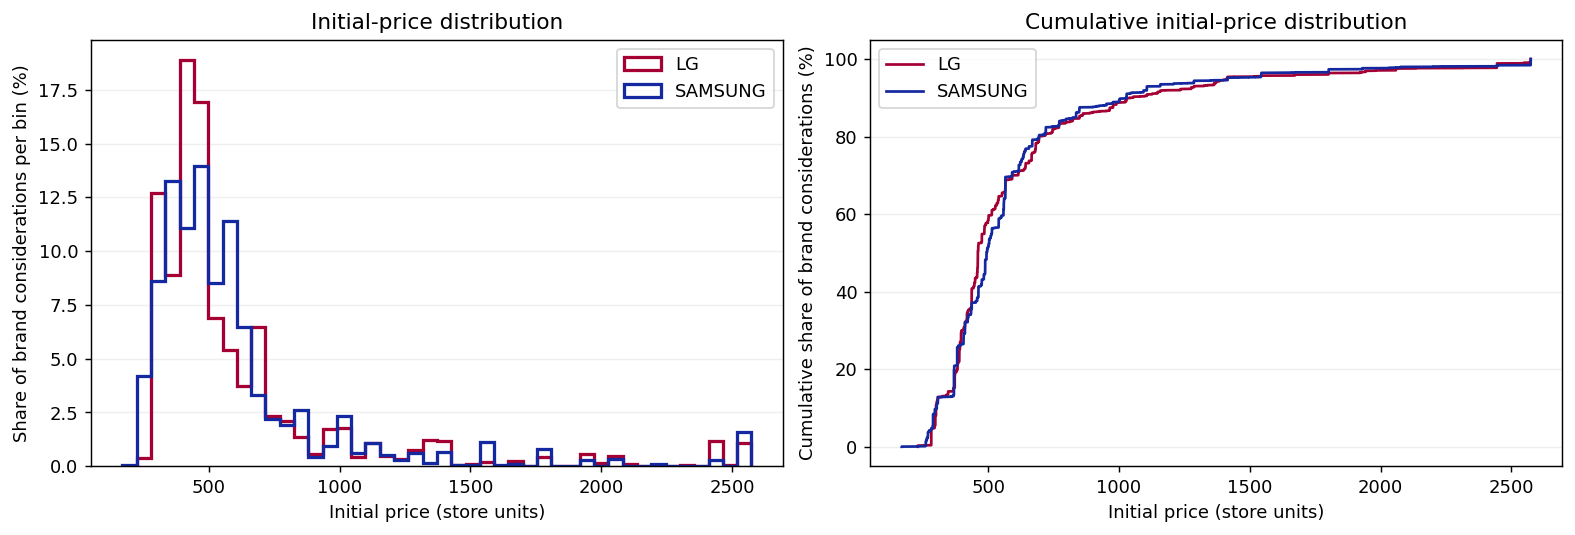

In [12]:
# 10. Compare full initial-price distributions and quantiles on the same scale
# Each consideration is weighted once. Repeated event prices would overweight busy sessions.
# Store currency is unidentified; do not label this axis EUR or USD.
quantile_levels = [0, .01, .05, .25, .50, .75, .95, .99, 1]
price_quantiles = baseline_full.groupby('brand')['initial_price'].quantile(quantile_levels).unstack()
price_quantiles.columns = ['min', 'p01', 'p05', 'p25', 'median', 'p75', 'p95', 'p99', 'max']
display(price_quantiles)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
bins = np.linspace(baseline_full['initial_price'].min(), baseline_full['initial_price'].max(), 45)
for brand in BRANDS:
    values = baseline_full.loc[baseline_full['brand'].eq(brand), 'initial_price']
    axes[0].hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
                 histtype='step', linewidth=1.8, color=BRAND_COLORS[brand], label=brand.upper())
    ordered = np.sort(values.to_numpy())
    axes[1].plot(ordered, 100 * np.arange(1, len(ordered) + 1) / len(ordered),
                 color=BRAND_COLORS[brand], label=brand.upper())
axes[0].set(title='Initial-price distribution', xlabel='Initial price (store units)',
            ylabel='Share of brand considerations per bin (%)')
axes[1].set(title='Cumulative initial-price distribution', xlabel='Initial price (store units)',
            ylabel='Cumulative share of brand considerations (%)')
for ax in axes:
    ax.legend(); ax.grid(axis='y', alpha=.2)
plt.show()
# Overlapping prices support a comparison over some of the same price range.
# They do not establish equal screen size, technology, quality, availability or visitor intent.


In [13]:
# 11. Product concentration: rank by considerations and purchase outcomes separately
# 'Most viewed' below means the most eligible consideration rows, not repeated view events.
# 'Most purchased' means binary purchase outcomes, not units sold or unique orders.
product_summary = baseline_full.groupby(['brand', 'product_id']).agg(
    consideration_rows=('Y', 'size'), purchase_outcomes=('Y', 'sum'),
    users=('user_id', 'nunique'), median_initial_price=('initial_price', 'median')).reset_index()
product_summary['conversion_rate'] = product_summary['purchase_outcomes'] / product_summary['consideration_rows']
product_summary['share_of_brand_rows'] = product_summary['consideration_rows'] / product_summary.groupby('brand')['consideration_rows'].transform('sum')
most_viewed_products = product_summary.sort_values(
    ['brand', 'consideration_rows', 'product_id'], ascending=[True, False, True])
most_purchased_products = product_summary.sort_values(
    ['brand', 'purchase_outcomes', 'product_id'], ascending=[True, False, True])
product_concentration_rows = []
for brand, ranked in most_viewed_products.groupby('brand', sort=False):
    for top_n in [1, 5, 10]:
        top = ranked.head(top_n)
        product_concentration_rows.append({
            'brand': brand, 'top_n_by_considerations': top_n, 'products_selected': len(top),
            'consideration_rows': int(top['consideration_rows'].sum()),
            'share_of_brand_rows_pct': 100 * top['consideration_rows'].sum() / ranked['consideration_rows'].sum(),
            'purchase_outcomes': int(top['purchase_outcomes'].sum()),
            'share_of_brand_purchases_pct': 100 * top['purchase_outcomes'].sum() / ranked['purchase_outcomes'].sum()
        })
product_concentration = pd.DataFrame(product_concentration_rows)
display(product_concentration)
display(most_viewed_products.groupby('brand', sort=False).head(5))
display(most_purchased_products.groupby('brand', sort=False).head(5))
top5_check = product_concentration.loc[product_concentration['top_n_by_considerations'].eq(5),
                                      ['brand', 'share_of_brand_rows_pct']].copy()
top5_check['reference_rounded_pct'] = top5_check['brand'].map({'lg': 42.3, 'samsung': 52.4})
top5_check['matches_at_1_decimal'] = top5_check['share_of_brand_rows_pct'].round(1).eq(top5_check['reference_rounded_pct'])
display(top5_check)
# Large shares imply that the average brand comparison also reflects the observed assortment.


,brand,top_n_by_considerations,products_selected,consideration_rows,share_of_brand_rows_pct,purchase_outcomes,share_of_brand_purchases_pct
0,lg,1,1,2723,12.2586,64,12.6733
1,lg,5,5,9398,42.3086,247,48.9109
2,lg,10,10,13226,59.5417,351,69.5050
3,samsung,1,1,9106,17.3451,459,27.9027
4,samsung,5,5,27500,52.3820,1036,62.9787
5,samsung,10,10,37168,70.7975,1355,82.3708


,brand,product_id,consideration_rows,purchase_outcomes,users,median_initial_price,conversion_rate,share_of_brand_rows
92,lg,P000640,2723,64,2649,298.3100,0.0235,0.1226
34,lg,P000499,2416,74,2356,389.9200,0.0306,0.1088
12,lg,P000463,1635,29,1552,434.7600,0.0177,0.0736
26,lg,P000478,1510,51,1449,460.5000,0.0338,0.0680
80,lg,P000617,1114,29,1049,680.3000,0.0260,0.0502
136,samsung,P000507,9106,459,8670,381.7200,0.0504,0.1735
145,samsung,P000554,6865,212,6614,501.9200,0.0309,0.1308
139,samsung,P000517,4394,132,4261,296.4400,0.0300,0.0837
170,samsung,P000581,4110,151,3927,566.0100,0.0367,0.0783
146,samsung,P000555,3025,82,2914,437.3300,0.0271,0.0576


,brand,product_id,consideration_rows,purchase_outcomes,users,median_initial_price,conversion_rate,share_of_brand_rows
34,lg,P000499,2416,74,2356,389.9200,0.0306,0.1088
92,lg,P000640,2723,64,2649,298.3100,0.0235,0.1226
26,lg,P000478,1510,51,1449,460.5000,0.0338,0.0680
38,lg,P000513,1023,33,1002,383.0200,0.0323,0.0461
77,lg,P000614,1011,33,968,457.9300,0.0326,0.0455
136,samsung,P000507,9106,459,8670,381.7200,0.0504,0.1735
145,samsung,P000554,6865,212,6614,501.9200,0.0309,0.1308
170,samsung,P000581,4110,151,3927,566.0100,0.0367,0.0783
139,samsung,P000517,4394,132,4261,296.4400,0.0300,0.0837
142,samsung,P000541,2850,109,2742,627.8100,0.0382,0.0543


,brand,share_of_brand_rows_pct,reference_rounded_pct,matches_at_1_decimal
1,lg,42.3086,42.3000,True
4,samsung,52.3820,52.4000,True


In [14]:
# 12. User concentration and repeated observations
# Count user-session pairs within each user; shared session IDs across different people
# therefore cannot merge their activity. Users may consider both brands and many products.
user_summary = baseline_full.groupby('user_id').agg(
    consideration_rows=('Y', 'size'), sessions=('session_id', 'nunique'),
    brands_viewed=('brand', 'nunique'), products_viewed=('product_id', 'nunique'),
    purchase_outcomes=('Y', 'sum')).reset_index()
user_distribution = user_summary.drop(columns='user_id').describe(percentiles=[.5, .9, .95, .99])
display(user_distribution)
repeated_users = user_summary['consideration_rows'].gt(1)
user_concentration = pd.DataFrame({
    'check': ['Distinct users', 'Users with multiple consideration rows',
              'Rows contributed by repeated users', 'Share of rows from repeated users (%)',
              'Users considering both brands'],
    'value': [len(user_summary), int(repeated_users.sum()),
              int(user_summary.loc[repeated_users, 'consideration_rows'].sum()),
              100 * user_summary.loc[repeated_users, 'consideration_rows'].sum() / len(baseline_full),
              int(user_summary['brands_viewed'].eq(2).sum())]
})
display(user_concentration)
ranked_users = user_summary.sort_values(['consideration_rows', 'user_id'], ascending=[False, True])
active_user_rows = []
for label, number in [('Top 10 users', min(10, len(ranked_users))),
                      ('Top 1% of users (rounded up)', int(np.ceil(.01 * len(ranked_users))))]:
    top = ranked_users.head(number)
    active_user_rows.append({'group': label, 'users_selected': len(top),
                             'consideration_rows': int(top['consideration_rows'].sum()),
                             'share_of_all_rows_pct': 100 * top['consideration_rows'].sum() / len(baseline_full),
                             'purchase_outcomes': int(top['purchase_outcomes'].sum())})
display(pd.DataFrame(active_user_rows))
user_brand_summary = baseline_full.groupby(['brand', 'user_id']).agg(
    consideration_rows=('Y', 'size'), sessions=('session_id', 'nunique'),
    purchase_outcomes=('Y', 'sum')).reset_index()
display(user_brand_summary.groupby('brand')['consideration_rows'].describe(percentiles=[.5, .9, .99]))
# Repeated observations matter for later uncertainty estimation. No inference rule is chosen here.
# Cross-brand users count once in the overall total and once in each relevant brand total.


,consideration_rows,sessions,brands_viewed,products_viewed,purchase_outcomes
count,"35,871.0000","35,871.0000","35,871.0000","35,871.0000","35,871.0000"
mean,2.0828,1.1260,1.1774,2.0050,0.0599
std,2.0806,0.5652,0.3820,1.8891,0.2698
min,1.0000,1.0000,1.0000,1.0000,0.0000
50%,1.0000,1.0000,1.0000,1.0000,0.0000
90%,4.0000,1.0000,2.0000,4.0000,0.0000
95%,6.0000,2.0000,2.0000,5.0000,1.0000
99%,10.0000,3.0000,2.0000,10.0000,1.0000
max,51.0000,30.0000,2.0000,33.0000,11.0000


,check,value
0,Distinct users,"35,871.0000"
1,Users with multiple consideration rows,"15,561.0000"
2,Rows contributed by repeated users,"54,402.0000"
3,Share of rows from repeated users (%),72.8156
4,Users considering both brands,"6,364.0000"


,group,users_selected,consideration_rows,share_of_all_rows_pct,purchase_outcomes
0,Top 10 users,10,350,0.4685,1
1,Top 1% of users (rounded up),359,5304,7.0993,56


,count,mean,std,min,50%,90%,99%,max
brand,,,,,,,,
lg,"12,908.0000",1.7209,1.6173,1.0000,1.0000,3.0000,8.0000,29.0000
samsung,"29,327.0000",1.7901,1.5193,1.0000,1.0000,3.0000,8.0000,33.0000


In [15]:
# 13. Monthly composition and consistency
# Counts and outcomes can be summed across first-view months; unique users/products cannot,
# because the same user/product can appear in both months. Monthly rates are not averaged equally.
monthly_composition = monthly_summary.copy()
monthly_composition['share_of_brand_rows_pct'] = (
    100 * monthly_composition['consideration_rows'] /
    monthly_composition.groupby('brand')['consideration_rows'].transform('sum'))
display(monthly_composition)
additive = ['consideration_rows', 'purchase_outcomes', 'eligible_cart_rows', 'purchase_after_cart_rows']
pd.testing.assert_frame_equal(
    monthly_summary.groupby('brand')[additive].sum().sort_index(),
    overall_summary.set_index('brand')[additive].sort_index(), check_dtype=False)
monthly_rates = monthly_summary.pivot(index='month', columns='brand', values='view_to_purchase')
monthly_rates['LG_minus_Samsung_pp'] = 100 * (monthly_rates['lg'] - monthly_rates['samsung'])
display(monthly_rates)
# A negative gap in both observed months is descriptive consistency, not evidence of annual stability.


,brand,month,consideration_rows,purchase_outcomes,eligible_cart_rows,purchase_after_cart_rows,purchases_without_cart_path,purchases_with_no_eligible_cart,users,products,view_to_purchase,view_to_cart,cart_to_purchase,share_of_brand_rows_pct
0,lg,2019-10,6770,183,210,94,89,89,4176,95,0.0270,0.0310,0.4476,30.4776
1,lg,2019-11,15443,322,863,280,42,42,8914,101,0.0209,0.0559,0.3244,69.5224
2,samsung,2019-10,18494,697,1053,487,210,210,11016,83,0.0377,0.0569,0.4625,35.2273
3,samsung,2019-11,34005,948,2258,843,105,105,18834,85,0.0279,0.0664,0.3733,64.7727


brand,lg,samsung,LG_minus_Samsung_pp
month,,,
2019-10,0.0270,0.0377,-1.0657
2019-11,0.0209,0.0279,-0.7027


In [16]:
# 14. Prepare named sensitivity samples without overwriting the baseline
# This is an explicit exploratory choice, not an official threshold or product matching.
# Options: 'central_1_99', 'min_max', or 'defer' (no price restriction until discussion).
# Inspect the quantiles and plot above before interpreting the selected restriction.
# User decision for this session: inspect distributions first; no price filter is applied.
COMMON_PRICE_RULE = 'defer'
sensitivity_samples = {'baseline_full': baseline_full}
sample_notes = {'baseline_full': 'All eligible LG/Samsung TV considerations under the strict-after rule.'}
if COMMON_PRICE_RULE in ['central_1_99', 'min_max']:
    lower_column, upper_column = ('p01', 'p99') if COMMON_PRICE_RULE == 'central_1_99' else ('min', 'max')
    common_price_lower = float(price_quantiles[lower_column].max())
    common_price_upper = float(price_quantiles[upper_column].min())
    assert common_price_lower < common_price_upper, 'No usable overlapping price interval.'
    common_price = baseline_full.loc[baseline_full['initial_price'].between(
        common_price_lower, common_price_upper, inclusive='both')].copy()
    sensitivity_samples['common_price'] = common_price
    sample_notes['common_price'] = (
        f'{COMMON_PRICE_RULE}: {common_price_lower:.2f} <= initial_price <= {common_price_upper:.2f}; '
        'comparison applies only to this price range, not equivalent product specifications.')
elif COMMON_PRICE_RULE != 'defer':
    raise ValueError('Unknown COMMON_PRICE_RULE.')

# Remove the most-considered product within EACH brand, using volume rather than conversion.
# If volumes tie, product_id determines the selection reproducibly; inspect any tie before interpretation.
removed_top_products = most_viewed_products.groupby('brand', sort=False).head(1).copy()
excluded_ids = removed_top_products['product_id']
exclude_top_viewed = baseline_full.loc[~baseline_full['product_id'].isin(excluded_ids)].copy()
sensitivity_samples['exclude_top_viewed'] = exclude_top_viewed
sample_notes['exclude_top_viewed'] = 'Exclude one most-considered product per brand; the observed assortment changes.'
display(removed_top_products)
display(pd.DataFrame([{'sample': name, 'rule_and_population': note} for name, note in sample_notes.items()]))
# No user or timing exclusion is silently applied; these remain documented choices for tutor feedback.


,brand,product_id,consideration_rows,purchase_outcomes,users,median_initial_price,conversion_rate,share_of_brand_rows
92,lg,P000640,2723,64,2649,298.3100,0.0235,0.1226
136,samsung,P000507,9106,459,8670,381.7200,0.0504,0.1735


,sample,rule_and_population
0,baseline_full,All eligible LG/Samsung TV considerations unde...
1,exclude_top_viewed,Exclude one most-considered product per brand;...


In [17]:
# 15. Recompute every denominator and raw KPI for each sensitivity sample
# A restricted sample answers a narrower question. Compare its composition as well as its gap.
# These are RAW conversion comparisons; no adjusted model is estimated in this session.
sensitivity_summary = pd.concat([
    journey_kpis(sample, ['brand']).assign(sample=name)
    for name, sample in sensitivity_samples.items()
], ignore_index=True)
sensitivity_kpis = kpis_as_long_table(sensitivity_summary, ['sample', 'brand'])
sensitivity_gaps = sensitivity_summary.pivot(index='sample', columns='brand', values='view_to_purchase')
sensitivity_gaps['raw_LG_minus_Samsung_pp'] = 100 * (sensitivity_gaps['lg'] - sensitivity_gaps['samsung'])
sensitivity_gaps['change_from_baseline_gap_pp'] = (
    sensitivity_gaps['raw_LG_minus_Samsung_pp'] - sensitivity_gaps.loc['baseline_full', 'raw_LG_minus_Samsung_pp'])
sample_sizes = sensitivity_summary.groupby('sample')[['consideration_rows', 'purchase_outcomes']].sum()
sample_comparison = sample_sizes.join(sensitivity_gaps[['raw_LG_minus_Samsung_pp', 'change_from_baseline_gap_pp']])
display(sensitivity_summary)
display(sensitivity_kpis)
display(sample_comparison)
assert len(baseline_full) == int(overall_summary['consideration_rows'].sum()), 'Baseline was changed.'


,brand,consideration_rows,purchase_outcomes,eligible_cart_rows,purchase_after_cart_rows,purchases_without_cart_path,purchases_with_no_eligible_cart,users,products,view_to_purchase,view_to_cart,cart_to_purchase,sample
0,lg,22213,505,1073,374,131,131,12908,105,0.0227,0.0483,0.3486,baseline_full
1,samsung,52499,1645,3311,1330,315,315,29327,91,0.0313,0.0631,0.4017,baseline_full
2,lg,19490,441,905,315,126,126,11196,104,0.0226,0.0464,0.3481,exclude_top_viewed
3,samsung,43393,1186,2436,946,240,240,24808,90,0.0273,0.0561,0.3883,exclude_top_viewed


,sample,brand,KPI,numerator,denominator,rate,rate_pct
0,baseline_full,lg,View-to-purchase,505,22213,0.0227,2.2734
1,baseline_full,samsung,View-to-purchase,1645,52499,0.0313,3.1334
2,exclude_top_viewed,lg,View-to-purchase,441,19490,0.0226,2.2627
3,exclude_top_viewed,samsung,View-to-purchase,1186,43393,0.0273,2.7332
4,baseline_full,lg,View-to-cart,1073,22213,0.0483,4.8305
5,baseline_full,samsung,View-to-cart,3311,52499,0.0631,6.3068
6,exclude_top_viewed,lg,View-to-cart,905,19490,0.0464,4.6434
7,exclude_top_viewed,samsung,View-to-cart,2436,43393,0.0561,5.6138
8,baseline_full,lg,Cart-to-purchase,374,1073,0.3486,34.8555
9,baseline_full,samsung,Cart-to-purchase,1330,3311,0.4017,40.1691


,consideration_rows,purchase_outcomes,raw_LG_minus_Samsung_pp,change_from_baseline_gap_pp
sample,,,,
baseline_full,74712,2150,-0.8599,0.0000
exclude_top_viewed,62883,1627,-0.4705,0.3895


In [18]:
# 16. End-of-session reconciliation and questions for Tutorial I
# This summary distinguishes verified references from choices still requiring discussion.
session_checks = pd.DataFrame({
    'check': ['Unique analytical keys', 'Binary non-missing outcome',
              'Raw-file duplicate reference: 1,247', 'Shared-session reference: 4',
              'Exact duplicates leave the analytical table unchanged',
              'Cohort and rounded KPI references reproduced',
              'Top-five product shares reproduced at one decimal'],
    'passed': [not baseline_full.duplicated(KEY).any(),
               bool(baseline_full['Y'].notna().all() and baseline_full['Y'].isin([0, 1]).all()),
               exact_duplicate_count == 1247, len(shared_session_ids) == 4,
               duplicate_invariance_verified, references_match,
               bool(top5_check['matches_at_1_decimal'].all())]
})
display(session_checks)
print('All end-of-session checks pass.' if session_checks['passed'].all() else
      'Investigate the failed checks; keep the observed values and document any discrepancy.')
# Tutorial question 1: Is the user-session-product unit and same-session, strict-after
# purchase definition suitable, including equal timestamps and end-of-window exposure?
# Tutorial question 2: Given price overlap and product concentration, which sample/control
# choices support a defensible brand comparison when specifications and availability are absent?
# Tutorial question 3: How should later uncertainty account for repeated users AND products?
# Proposed next-session models: M1 brand only; M2 brand + log(initial price) + first-view month.
# The present session estimates neither model and makes no causal or intervention claim.
# All tables are reproducibly generated in memory. No dataset is copied into the repository.
# Before committing, clear the manual sequence cell's outputs, which contain raw event rows.


,check,passed
0,Unique analytical keys,True
1,Binary non-missing outcome,True
2,"Raw-file duplicate reference: 1,247",True
3,Shared-session reference: 4,True
4,Exact duplicates leave the analytical table un...,True
5,Cohort and rounded KPI references reproduced,True
6,Top-five product shares reproduced at one decimal,True


All end-of-session checks pass.
